In [ ]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from tqdm import tqdm

In [ ]:
ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

TRAIN_IMAGES = os.path.join(ROOT, "train/images")
TRAIN_MASKS = os.path.join(ROOT, "train/masks")

VAL_IMAGES = os.path.join(ROOT, "val/images")
VAL_MASKS = os.path.join(ROOT, "val/masks")

TEST_IMAGES = os.path.join(ROOT, "test/images")
TEST_MASKS = os.path.join(ROOT, "test/masks")

OUTPUT_ROOT = "/content/drive/MyDrive/Image data/UNet outputs"

os.makedirs(OUTPUT_ROOT, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_ROOT, "figures"), exist_ok=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import rasterio
import numpy as np

MASK_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/masks"

# Safely check if directory exists first
if not os.path.exists(MASK_DIR):
    print(f"Directory not found: {MASK_DIR}")
    print("\nAvailable items in '/content/drive/MyDrive/':")
    if os.path.exists('/content/drive/MyDrive/'):
        print(os.listdir('/content/drive/MyDrive/'))
    else:
        print("Google Drive is not mounted or not accessible.")
else:
    unique_values = set()
    for f in os.listdir(MASK_DIR):
        if f.endswith(".tif"):
            with rasterio.open(os.path.join(MASK_DIR, f)) as src:
                data = src.read(1)
                unique_values.update(np.unique(data))
    print("Unique classes in mask:", unique_values)

{np.uint8(0), np.uint8(1)}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import rasterio

IMAGE_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/images"

sample = sorted(os.listdir(IMAGE_DIR))[0]

with rasterio.open(
    os.path.join(IMAGE_DIR, sample)
) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)

Width: 1024
Height: 1024
Bands: 3


In [ ]:
# ==========================================================
# 06_create UNET_dataset.py
# UNET Dataset Loader
# ==========================================================

import os
import numpy as np
import rasterio

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# ==========================================================
# SETTINGS
# ==========================================================

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

# ==========================================================
# DATASET CLASS
# ==========================================================

class BuildingDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".tif")
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        mask_name = image_name.replace(
            ".tif",
            "_mask.tif"
        )

        # -----------------------------------
        # IMAGE
        # -----------------------------------

        with rasterio.open(
            os.path.join(
                self.image_dir,
                image_name
            )
        ) as src:

            image = src.read()

        image = image.astype(
            np.float32
        ) / 255.0

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        # -----------------------------------
        # MASK
        # -----------------------------------

        with rasterio.open(
            os.path.join(
                self.mask_dir,
                mask_name
            )
        ) as src:

            mask = src.read(1)

        mask = torch.tensor(
            mask,
            dtype=torch.long
        )

        return image, mask

# ==========================================================
# DATASETS
# ==========================================================

train_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "train/images"
    ),

    os.path.join(
        ROOT,
        "train/masks"
    )
)

val_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "val/images"
    ),

    os.path.join(
        ROOT,
        "val/masks"
    )
)

test_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "test/images"
    ),

    os.path.join(
        ROOT,
        "test/masks"
    )
)

# ==========================================================
# DATALOADERS
# ==========================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2
)

# ==========================================================
# VALIDATION
# ==========================================================

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

images, masks = next(
    iter(train_loader)
)

print()

print("Image tensor:")
print(images.shape)

print()

print("Mask tensor:")
print(masks.shape)

print()

print("Image range:")
print(images.min().item(),
      images.max().item())

print()

print("Mask classes:")
print(torch.unique(masks))

Train: 145
Val: 20
Test: 43

Image tensor:
torch.Size([2, 3, 1024, 1024])

Mask tensor:
torch.Size([2, 1024, 1024])

Image range:
0.0 1.0

Mask classes:
tensor([0, 1])


In [ ]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(DEVICE)

cuda


In [ ]:
# creating folders for my outputs

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Image data/UNet outputs"

folders = [
    "models",
    "history",
    "figures",
    "predictions",
    "results"
]

for f in folders:
    os.makedirs(
        os.path.join(ROOT, f),
        exist_ok=True
    )

print("Folders created")

Folders created


In [ ]:
!pip install -q segmentation-models-pytorch
!pip install -q torchmetrics
!pip install -q albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.2 MB/s eta 0:00:00


In [ ]:
# ==========================================================
# CONFIGURATION
# ==========================================================

import os
import random
import numpy as np
import pandas as pd

import rasterio

import torch
import torch.nn as nn

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

import segmentation_models_pytorch as smp

import albumentations as A

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

from tqdm import tqdm

# ==========================================================
# PATHS
# ==========================================================

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

TRAIN_IMAGES = os.path.join(ROOT, "train/images")
TRAIN_MASKS = os.path.join(ROOT, "train/masks")

VAL_IMAGES = os.path.join(ROOT, "val/images")
VAL_MASKS = os.path.join(ROOT, "val/masks")

TEST_IMAGES = os.path.join(ROOT, "test/images")
TEST_MASKS = os.path.join(ROOT, "test/masks")

OUTPUT_ROOT = "/content/drive/MyDrive/Image data/UNet outputs"

# ==========================================================
# SETTINGS
# ==========================================================

NUM_CLASSES = 2

BATCH_SIZE = 2

EPOCHS = 50

LEARNING_RATE = 1e-4

PATIENCE = 10

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

Device: cuda


In [ ]:
# ==========================================================
# DATASET
# ==========================================================

class BuildingDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        augment=False
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".tif")
        ])

        self.augment = augment

        self.transform = A.Compose([

            A.HorizontalFlip(p=0.5),

            A.VerticalFlip(p=0.5),

            A.RandomRotate90(p=0.5)

        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        mask_name = image_name.replace(
            ".tif",
            "_mask.tif"
        )

        with rasterio.open(
            os.path.join(
                self.image_dir,
                image_name
            )
        ) as src:

            image = src.read(
                [1,2,3]
            )

        image = np.transpose(
            image,
            (1,2,0)
        )

        with rasterio.open(
            os.path.join(
                self.mask_dir,
                mask_name
            )
        ) as src:

            mask = src.read(1)

        if self.augment:

            augmented = self.transform(
                image=image,
                mask=mask
            )

            image = augmented["image"]
            mask = augmented["mask"]

        image = image.astype(
            np.float32
        ) / 255.0

        image = np.transpose(
            image,
            (2,0,1)
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.long
        )

        return image, mask

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

145
20
43


In [ ]:
#model

model = smp.Unet(

    encoder_name="resnet50",

    encoder_weights="imagenet",

    in_channels=3,

    classes=2

)

model = model.to(DEVICE)

print(model.__class__.__name__)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Unet


In [ ]:
#Loss

dice_loss = smp.losses.DiceLoss(
    mode="multiclass"
)

ce_loss = nn.CrossEntropyLoss()

def combined_loss(preds, targets):

    return (
        dice_loss(preds, targets)
        +
        ce_loss(preds, targets)
    )

In [ ]:
#optimizer

LEARNING_RATE = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

In [ ]:
scaler = torch.amp.GradScaler("cuda")

In [ ]:
#metrics function



In [ ]:
# ==========================================================
# METRICS
# ==========================================================

def calculate_metrics(
    preds,
    masks
):

    preds = torch.argmax(
        preds,
        dim=1
    )

    preds = preds.cpu().numpy().flatten()

    masks = masks.cpu().numpy().flatten()

    precision = precision_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    recall = recall_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    f1 = f1_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    intersection = np.logical_and(
        preds == 1,
        masks == 1
    ).sum()

    union = np.logical_or(
        preds == 1,
        masks == 1
    ).sum()

    iou = (
        intersection / union
        if union > 0
        else 0
    )

    return (
        precision,
        recall,
        f1,
        iou
    )

In [ ]:
#training variables

EPOCHS = 30
PATIENCE = 8

history = []

best_iou = 0

patience_counter = 0

In [ ]:
# ==========================================================
# TRAINING LOOP
# ==========================================================

for epoch in range(EPOCHS):

    print(
        f"\nEpoch {epoch+1}/{EPOCHS}"
    )

    # =====================================
    # TRAIN
    # =====================================

    model.train()

    train_loss = 0

    for images, masks in tqdm(
        train_loader
    ):

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        optimizer.zero_grad()

        with torch.amp.autocast(
            "cuda"
        ):

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        train_loss += loss.item()

    train_loss /= len(
        train_loader
    )

    # =====================================
    # VALIDATION
    # =====================================

    model.eval()

    val_loss = 0

    precisions = []
    recalls = []
    f1s = []
    ious = []

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                DEVICE
            )

            masks = masks.to(
                DEVICE
            )

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

            val_loss += loss.item()

            p,r,f,i = calculate_metrics(
                outputs,
                masks
            )

            precisions.append(p)
            recalls.append(r)
            f1s.append(f)
            ious.append(i)

    val_loss /= len(
        val_loader
    )

    precision = np.mean(
        precisions
    )

    recall = np.mean(
        recalls
    )

    f1 = np.mean(
        f1s
    )

    iou = np.mean(
        ious
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"IoU: {iou:.4f}"
    )

    print(
        f"F1: {f1:.4f}"
    )

    # =====================================
    # SAVE HISTORY
    # =====================================

    history.append({

        "epoch":
        epoch+1,

        "train_loss":
        train_loss,

        "val_loss":
        val_loss,

        "precision":
        precision,

        "recall":
        recall,

        "f1":
        f1,

        "iou":
        iou
    })

    # =====================================
    # BEST MODEL
    # =====================================

    if iou > best_iou:

        best_iou = iou

        patience_counter = 0

        torch.save(

    model.state_dict(),

    os.path.join(
        OUTPUT_ROOT,
        "models",
        "best_unet.pth"
    )
)
        print(
            "Best model saved."
        )

    else:

        patience_counter += 1

    # =====================================
    # EARLY STOPPING
    # =====================================

    if patience_counter >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break


Epoch 1/30


100%|██████████| 72/72 [00:48<00:00,  1.50it/s]


Train Loss: 0.5948
Val Loss: 0.4300
IoU: 0.6981
F1: 0.8130
Best model saved.

Epoch 2/30


100%|██████████| 72/72 [00:48<00:00,  1.47it/s]


Train Loss: 0.3309
Val Loss: 0.2871
IoU: 0.7517
F1: 0.8496
Best model saved.

Epoch 3/30


...

Train Loss: 0.0557
Val Loss: 0.0987
IoU: 0.8796
F1: 0.9348

Epoch 26/30


100%|██████████| 72/72 [00:47<00:00,  1.51it/s]


Train Loss: 0.0489
Val Loss: 0.1053
IoU: 0.8733
F1: 0.9309

Epoch 27/30


100%|██████████| 72/72 [00:47<00:00,  1.50it/s]


Train Loss: 0.0452
Val Loss: 0.1003
IoU: 0.8801
F1: 0.9348

Early stopping triggered.


In [ ]:
#loading the best model

In [ ]:
best_model_path = "/content/drive/MyDrive/Image data/UNet outputs/models/best_model.pth"

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model.eval()

print("Best model loaded.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Image data/UNet outputs/models/best_model.pth'

In [ ]:
#test evaluation

model.eval()

precisions = []
recalls = []
f1s = []
ious = []

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(DEVICE)

        masks = masks.to(DEVICE)

        outputs = model(images)

        p, r, f, i = calculate_metrics(
            outputs,
            masks
        )

        precisions.append(p)
        recalls.append(r)
        f1s.append(f)
        ious.append(i)

test_precision = np.mean(precisions)
test_recall = np.mean(recalls)
test_f1 = np.mean(f1s)
test_iou = np.mean(ious)

print("\n===== TEST RESULTS =====")

print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"IoU:       {test_iou:.4f}")

In [ ]:
history_df = pd.DataFrame(history)

history_df.to_csv(

    os.path.join(
        OUTPUT_ROOT,
        "training_history.csv"
    ),

    index=False
)

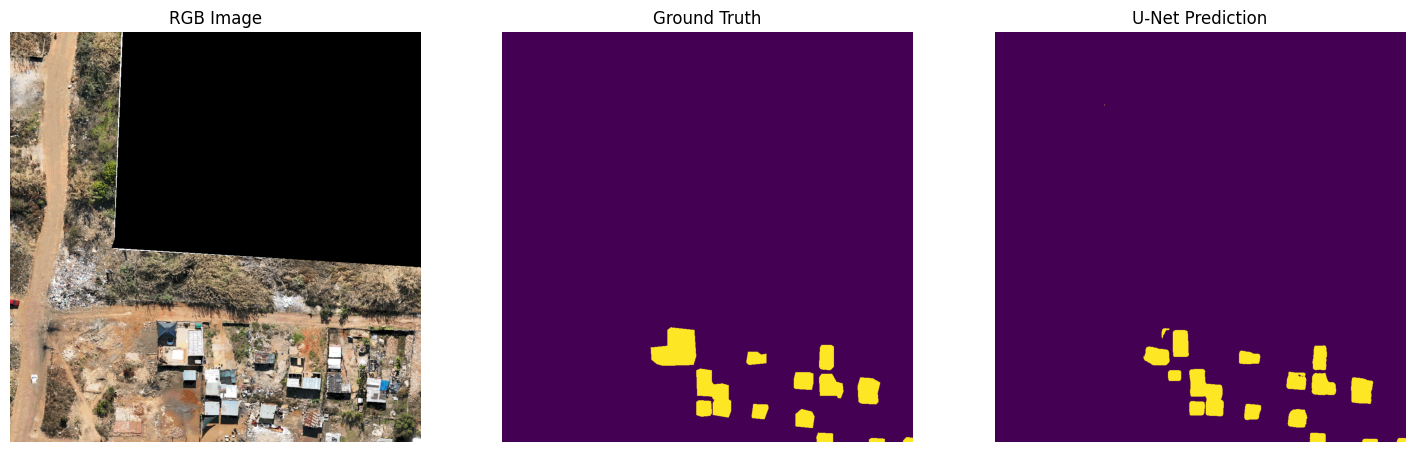

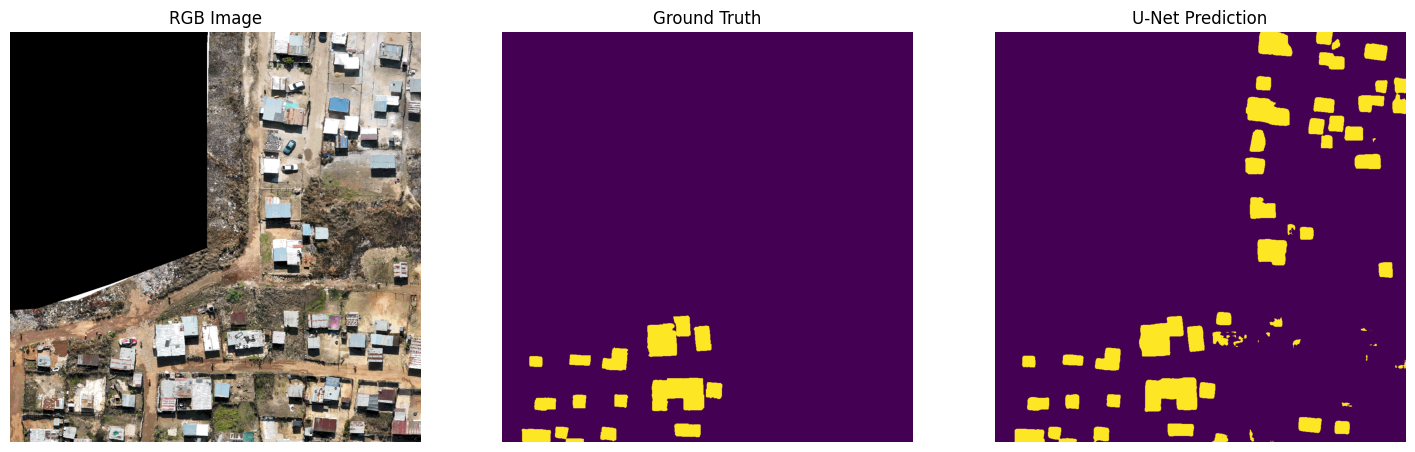

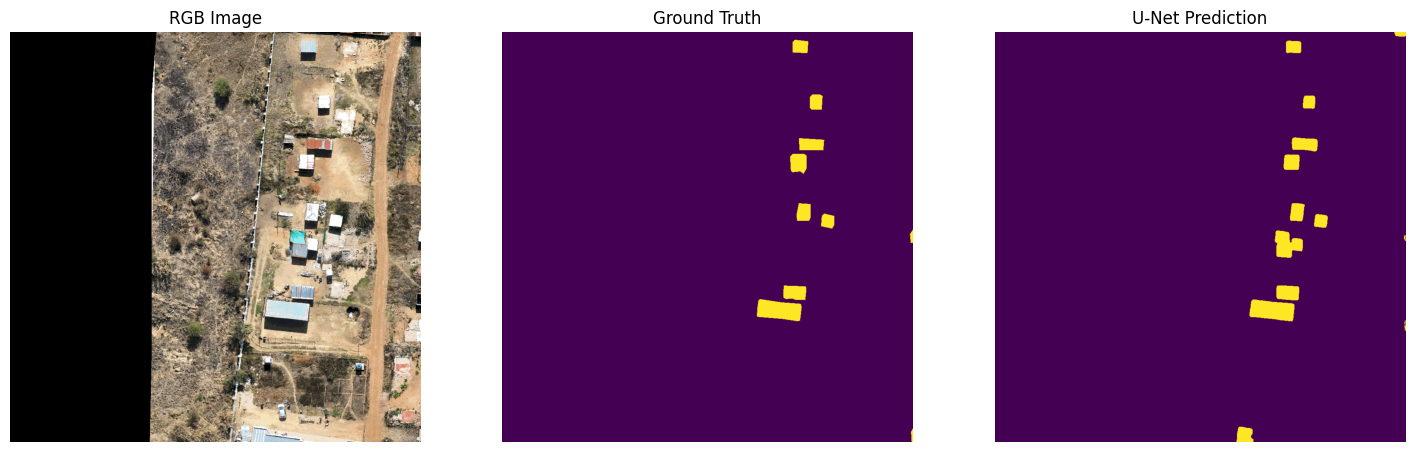

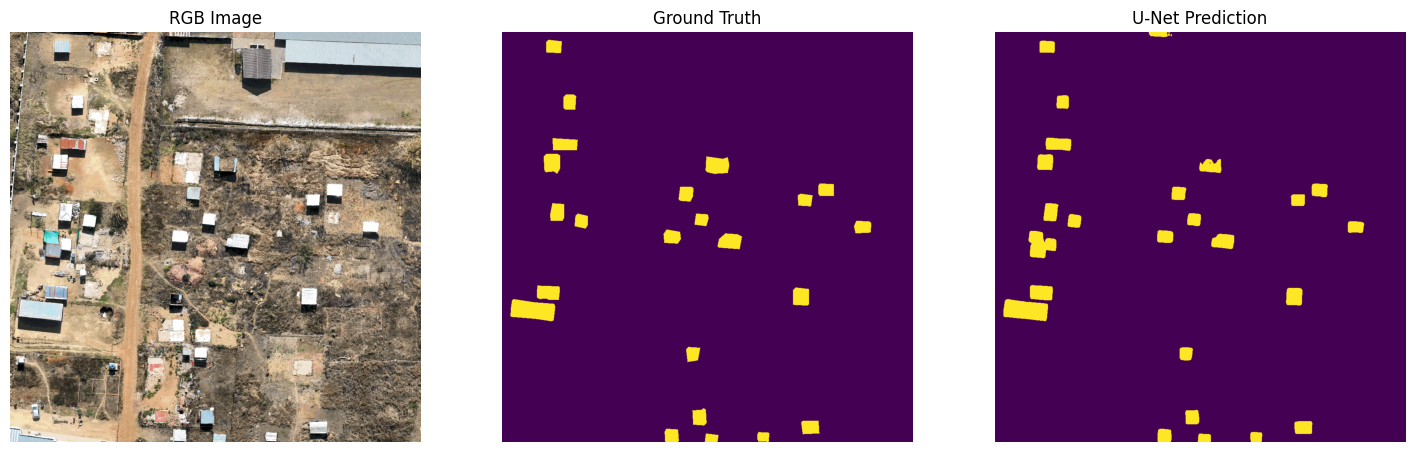

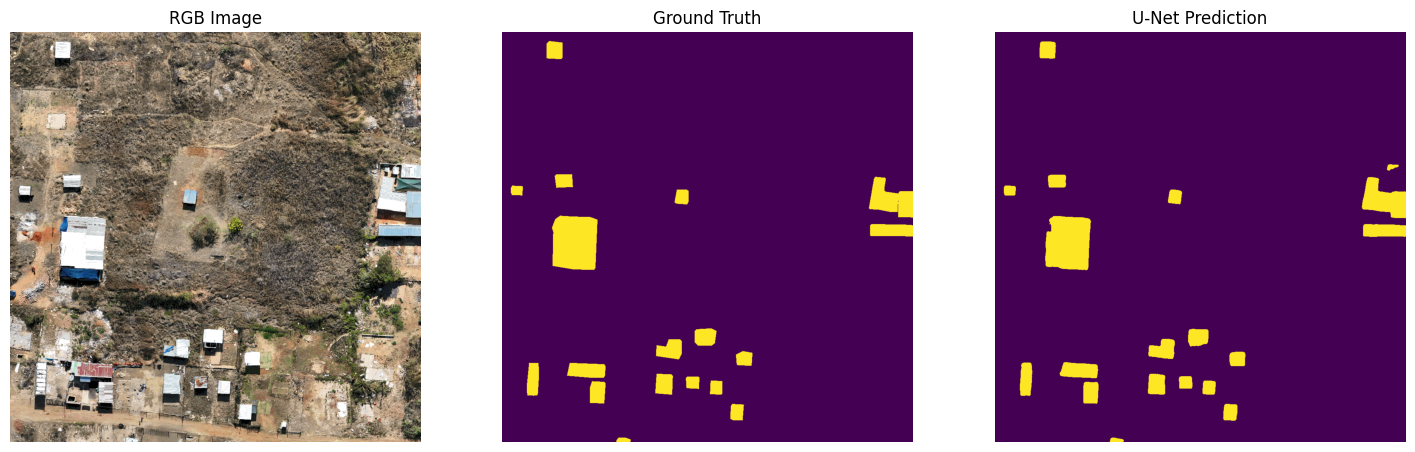

In [ ]:
# ==========================================================
# VISUALIZE TEST PREDICTIONS
# ==========================================================

import matplotlib.pyplot as plt

NUM_SAMPLES = 5

for i in range(NUM_SAMPLES):

    image, mask = test_dataset[i]

    with torch.no_grad():

        pred = model(
            image.unsqueeze(0).to(DEVICE)
        )

    pred = torch.argmax(
        pred,
        dim=1
    ).squeeze().cpu().numpy()

    image_np = (
        image.permute(1,2,0)
        .cpu()
        .numpy()
    )

    mask_np = mask.cpu().numpy()

    plt.figure(figsize=(18,6))

    # RGB

    plt.subplot(1,3,1)

    plt.imshow(image_np)

    plt.title("RGB Image")

    plt.axis("off")

    # Ground Truth

    plt.subplot(1,3,2)

    plt.imshow(mask_np)

    plt.title("Ground Truth")

    plt.axis("off")

    # Prediction

    plt.subplot(1,3,3)

    plt.imshow(pred)

    plt.title("U-Net Prediction")

    plt.axis("off")

    plt.show()

In [ ]:
#maybe might be different for semantic segmentation
image, target = test_dataset[123]

print(image.shape)

In [ ]:
#Prediction

with torch.no_grad():

    prediction = model(
        [image.to(DEVICE)]
    )[123]

In [ ]:
#creating one combined prediction mask

import numpy as np

height = image.shape[1]
width = image.shape[2]

prediction_mask = np.zeros(
    (height, width),
    dtype=np.uint8
)

masks = prediction["masks"].cpu().numpy()
scores = prediction["scores"].cpu().numpy()

keep = scores > 0.5

for m in masks[keep]:

    prediction_mask = np.maximum(
        prediction_mask,
        (m[0] > 0.5).astype(np.uint8)
    )

print(np.unique(prediction_mask))

In [ ]:
#get raster metadata

import rasterio

test_image_name = test_dataset.images[0]

test_image_path = os.path.join(
    TEST_IMAGES,
    test_image_name
)

with rasterio.open(test_image_path) as src:

    profile = src.profile.copy()

    transform = src.transform

In [ ]:
#saving my prediction as GeoTiFF

profile.update(

    dtype=rasterio.uint8,

    count=1,

    compress="lzw"
)

output_tif = (
    "/content/drive/MyDrive/Image data/MaskRCNN/predictions/"
    "maskrcnn_prediction.tif"
)

os.makedirs(
    os.path.dirname(output_tif),
    exist_ok=True
)

with rasterio.open(
    output_tif,
    "w",
    **profile
) as dst:

    dst.write(
        prediction_mask,
        1
    )

print(output_tif)